In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("paket_a_transaksi_pos_2024_2025.csv")

print("Dataset berhasil dibaca!")
print("Jumlah baris dan kolom:", df.shape)

df.head()

Dataset berhasil dibaca!
Jumlah baris dan kolom: (5030, 9)


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [3]:
print("Jumlah missing value:")
print(df.isnull().sum())

Jumlah missing value:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


In [4]:
print("Total missing value:",
      df.isnull().sum().sum())

Total missing value: 261


In [5]:
df["kode_kasir"] = df["kode_kasir"].fillna(
    "TIDAK_DIKETAHUI"
)

print("Missing value setelah penanganan:")
print(df.isnull().sum())

Missing value setelah penanganan:
id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64


In [6]:
# Memperbaiki format tanggal
df["tanggal"] = pd.to_datetime(
    df["tanggal"],
    errors="coerce",
    dayfirst=True,
    format="mixed"
)

# Memperbaiki format harga
df["harga_satuan"] = (
    df["harga_satuan"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

df["harga_satuan"] = pd.to_numeric(
    df["harga_satuan"],
    errors="coerce"
)

print(df[["tanggal", "harga_satuan"]].head())

     tanggal  harga_satuan
0 2025-02-06       13000.0
1 2024-12-28       21000.0
2 2024-04-09        7500.0
3 2025-07-30        6500.0
4 2025-03-26        6000.0


In [7]:
print("Duplikasi sebelum dihapus:",
      df.duplicated().sum())

df = df.drop_duplicates()

print("Duplikasi setelah dihapus:",
      df.duplicated().sum())

print("Jumlah data setelah dibersihkan:",
      df.shape)

Duplikasi sebelum dihapus: 30
Duplikasi setelah dihapus: 0
Jumlah data setelah dibersihkan: (5000, 9)


In [12]:
# Mengambil tahun dari tanggal transaksi
df["tahun"] = df["tanggal"].dt.year

# Memilih transaksi tahun 2024 dan 2025
df_tahun = df[df["tahun"].isin([2024, 2025])]

# Menghitung pendapatan per tahun
pendapatan_tahunan = (
    df_tahun.groupby("tahun")["pendapatan"]
    .sum()
    .reindex([2024, 2025], fill_value=0)
)

print("TOTAL PENDAPATAN PER TAHUN")
print(pendapatan_tahunan)

TOTAL PENDAPATAN PER TAHUN
tahun
2024    383804800.0
2025    254151475.0
Name: pendapatan, dtype: float64


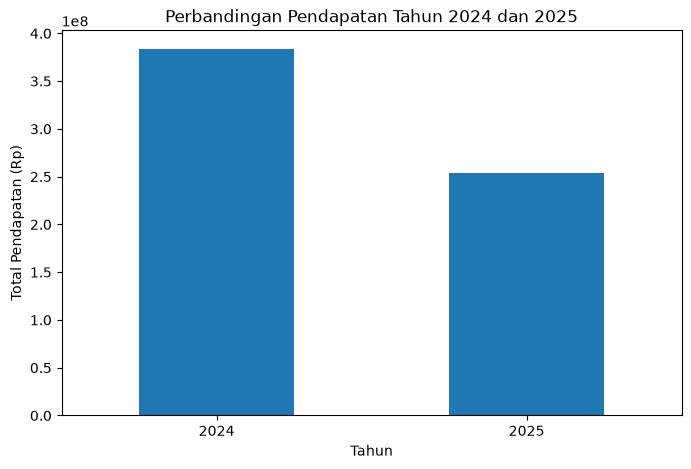

In [14]:
pendapatan_tahunan.plot(
    kind="bar",
    figsize=(8, 5),
    title="Perbandingan Pendapatan Tahun 2024 dan 2025"
)

plt.xlabel("Tahun")
plt.ylabel("Total Pendapatan (Rp)")
plt.xticks(rotation=0)
plt.show()

In [11]:
# Menyimpan dataset bersih
df.to_csv(
    "dataset_transaksi_bersih.csv",
    index=False
)

# Menyimpan hasil pendapatan tahunan
pendapatan_tahunan.to_csv(
    "hasil_pendapatan_tahunan.csv"
)

print("File berhasil disimpan!")

File berhasil disimpan!
